In [1]:
from pathlib import Path
import os
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

## Step 2: Define the dataset path

In [2]:
from pathlib import Path

DATASET_DIR = Path("../plantvillage/raw/color")

classes = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

for class_name in classes:
    folder = DATASET_DIR / class_name
    print(f"{class_name}: {len(list(folder.glob('*')))} images")

Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images


## Step 3: Create a class distribution table

In [3]:
class_counts = {}

for class_name in classes:
    folder = DATASET_DIR / class_name
    class_counts[class_name.replace("Potato___", "")] = len(
        list(folder.glob("*"))
    )

class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Disease Class", "Number of Images"]
)

class_distribution["Percentage"] = (
    class_distribution["Number of Images"]
    / class_distribution["Number of Images"].sum()
    * 100
)

display(class_distribution)

print("Total images:", class_distribution["Number of Images"].sum())

,Disease Class,Number of Images,Percentage
0,Early_blight,1000,46.468401
1,Late_blight,1000,46.468401
2,healthy,152,7.063197


Total images: 2152


Important observation: The dataset is imbalanced. Healthy leaves represent only 7.06% of the images, compared with approximately 46.47% for each disease class.

This matters because a model trained on this distribution may become less effective at identifying healthy leaves.

We'll address this during data preparation rather than deleting images now.

## Step 4: Visualize the class distribution

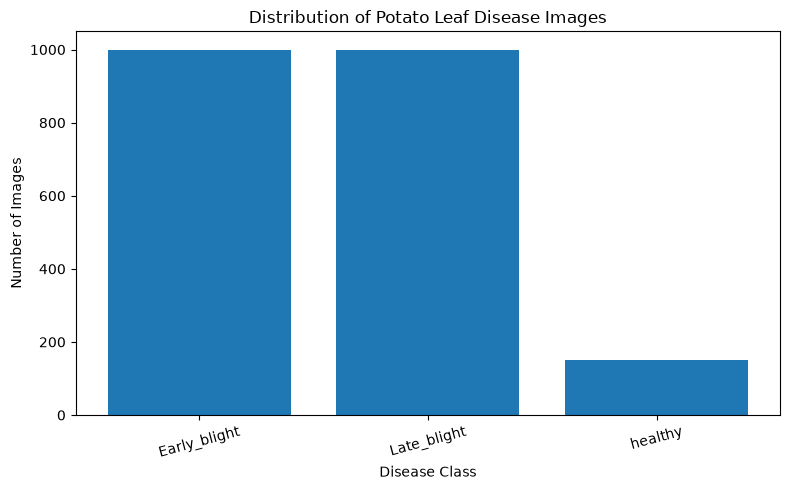

In [4]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_distribution["Disease Class"],
    class_distribution["Number of Images"]
)

plt.title("Distribution of Potato Leaf Disease Images")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

What this tells us: The model will have fewer healthy-leaf examples to learn from. We'll consider techniques such as class weighting and data augmentation during training.

## Step 5: Display sample images

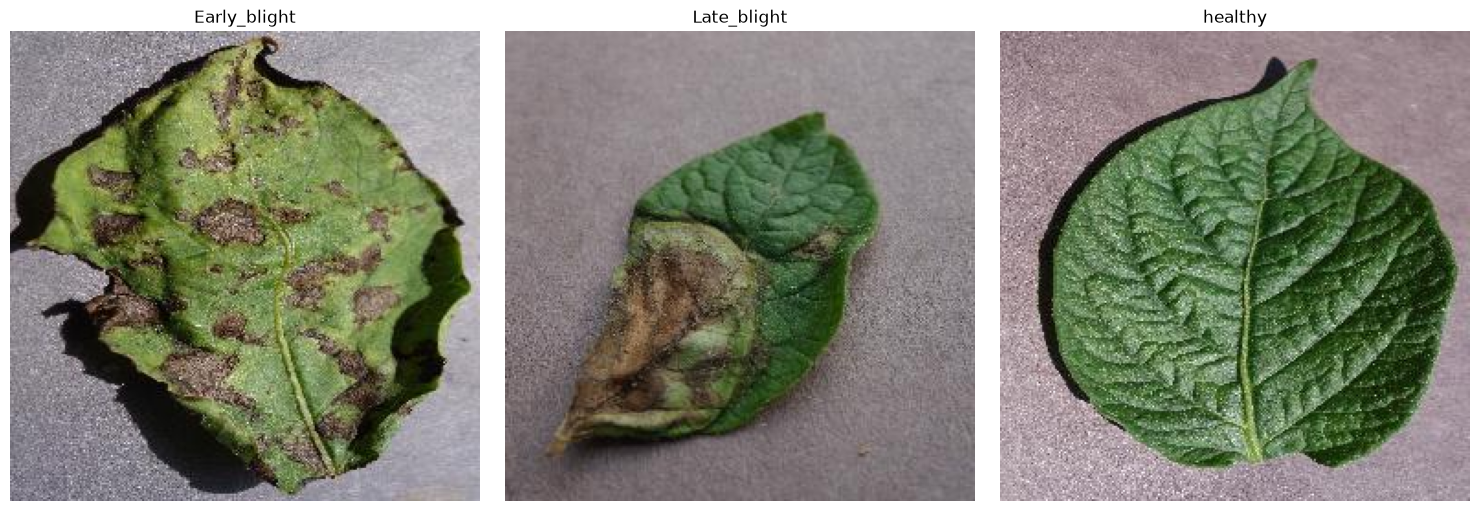

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, class_name in zip(axes, classes):
    folder = DATASET_DIR / class_name
    image_path = next(folder.glob("*.JPG"))

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name.replace("Potato___", ""))
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 6: Inspect image dimensions
Before training a CNN, we need to understand the image sizes.

In [6]:
image_sizes = []

for class_name in classes:
    folder = DATASET_DIR / class_name

    for image_path in folder.glob("*.JPG"):
        with Image.open(image_path) as img:
            image_sizes.append({
                "Class": class_name.replace("Potato___", ""),
                "Width": img.width,
                "Height": img.height
            })

image_dimensions = pd.DataFrame(image_sizes)

display(image_dimensions.describe())

print("Unique image dimensions:")
print(image_dimensions[["Width", "Height"]].drop_duplicates())

,Width,Height
count,2152.0,2152.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


Unique image dimensions:
   Width  Height
0    256     256


All 2,152 images have identical dimensions: 256 × 256 pixels.

This is useful because:
- The images already have a consistent size.
- We don't need additional resizing just to standardize dimensions.
- They are suitable for CNN input after normalization and preprocessing.

## Step 7: Check for corrupted images

Before preparing the training dataset, let's verify that the image files can all be opened.

In [7]:
corrupted_images = []

for class_name in classes:
    folder = DATASET_DIR / class_name

    for image_path in folder.glob("*.JPG"):
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(str(image_path))

print("Total images checked:", len(image_sizes))
print("Corrupted images:", len(corrupted_images))

Total images checked: 2152
Corrupted images: 0


## Step 8: Save the exploration results

save the class distribution and image dimensions so it can be used in project report.

In [8]:
class_distribution.to_csv(
    "../dataset/class_distribution.csv",
    index=False
)

image_dimensions.to_csv(
    "../dataset/image_dimensions.csv",
    index=False
)

print("Exploration results saved successfully.")

Exploration results saved successfully.
